# Diabetic Retinopathy using MLP

## 1. Import Library

In [1]:
import numpy as np
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import time
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
import joblib
import pickle
from sklearn.neural_network import MLPClassifier

## 2. Load Data

In [ ]:
with open("../../../data/processed/aptos/full_aptos/full_dataset.pkl", "rb") as f: #[cite: 1]
    data = pickle.load(f)

In [3]:
with open("../../../data/processed/aptos/test_images/sample_dataset.pkl", "rb") as f:
    data_test = pickle.load(f)

## 3. Data Preprocessing

In [4]:
X = data['data']
y = data['labels']
class_names = data['class_names']
IMG_SIZE = X.shape[1]

In [5]:
N = X.shape[0]
X_flatten = X.reshape(N, -1) # Chuyển từ (N, 300, 300, 3) thành (N, 270000)
print(f"Kích thước sau khi duỗi: {X_flatten.shape}")

Kích thước sau khi duỗi: (250, 270000)


In [6]:
NUM_CLASSES = len(class_names)
x_train, x_val, y_train, y_val = train_test_split(
    X_flatten,y, test_size=0.2, random_state=42, stratify=y
)
print(f'Số mẫu: {len(y_train)} | Số lớp: {NUM_CLASSES} | Kích thước ảnh: {IMG_SIZE}x{IMG_SIZE}')

Số mẫu: 200 | Số lớp: 5 | Kích thước ảnh: 300x300


In [7]:
x_test = data_test['data']
y_test = data_test['labels']
print(f'Số mẫu: {len(y_test)} | Số lớp: {NUM_CLASSES} | Kích thước ảnh: {IMG_SIZE}x{IMG_SIZE}')

Số mẫu: 366 | Số lớp: 5 | Kích thước ảnh: 300x300


In [8]:
X_flatten_test = x_test.reshape(x_test.shape[0], -1)

## 3. Khởi tạo và huấn luyện mô hình SVM

In [9]:
print("\nBắt đầu huấn luyện mô hình SVM (Có thể mất một lúc)...")
start_time = time.time()


Bắt đầu huấn luyện mô hình SVM (Có thể mất một lúc)...


In [10]:
# ======================
# 1. Khởi tạo Pipeline cho ẢNH
# ======================
pipeline_mlp_image = Pipeline([
    # Bước 1: Chuẩn hóa dữ liệu (BẮT BUỘC cho SVM để hội tụ nhanh)
    # Đưa các giá trị pixel từ dải [0, 255] về phân phối chuẩn (mean=0, variance=1)
    ("scaler", StandardScaler()),
    
    # Bước 2: Giảm chiều dữ liệu bằng PCA
    # Giữ lại số lượng thành phần chính giải thích được 95% phương sai của ảnh
    # Giúp giảm từ 270.000 chiều xuống còn vài trăm chiều, SVM sẽ chạy nhanh gấp chục lần
    ("pca", PCA(n_components=0.95, random_state=42)),
    
    # Bước 3: Mô hình phân loại SVM
    ("mlp", MLPClassifier(
        hidden_layer_sizes=(512, 256), # Tạo 2 lớp ẩn, lớp đầu 512 nơ-ron, lớp sau 256 nơ-ron
        activation='relu',             # Hàm kích hoạt chuẩn
        solver='adam',                 # Thuật toán tối ưu giống hệt Keras
        alpha=0.0001,                  # Tham số phạt L2 để chống Overfitting
        batch_size=32,                 # Đẩy dữ liệu vào theo từng cụm 32 ảnh
        max_iter=500,                  # Số vòng lặp tối đa
        early_stopping=True,           # Tự dừng nếu không tiến bộ
        random_state=42
    ))
])

# ======================
# 2. Cross-validation (StratifiedKFold)
# ======================
# n_splits=5 nghĩa là chia tập train thành 5 phần (K=5)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("Đang chạy 5-Fold Cross-validation (Sẽ mất thời gian do PCA và MLP tính toán)...")
scores = cross_val_score(
    pipeline_mlp_image,
    x_train,       # Truyền mảng đã duỗi phẳng
    y_train,            # Nhãn dạng số nguyên (0 -> 4)
    cv=skf,
    scoring="f1_macro", # Dùng macro f1 để đánh giá công bằng các nhãn hiếm
    n_jobs=-1           # Dùng toàn bộ nhân CPU
)

print("\nF1 từng fold:", scores)
print(f"F1 trung bình (Cross-validation): {np.mean(scores):.4f}")

Đang chạy 5-Fold Cross-validation (Sẽ mất thời gian do PCA và MLP tính toán)...



F1 từng fold: [0.32759228 0.38264411 0.36526611 0.32221238 0.48001019]
F1 trung bình (Cross-validation): 0.3755


In [11]:
# ======================
# 3. Train FINAL MODEL
# ======================
print("\nĐang huấn luyện mô hình FINAL trên toàn bộ tập Train...")
pipeline_mlp_image.fit(x_train, y_train)


Đang huấn luyện mô hình FINAL trên toàn bộ tập Train...


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('scaler', ...), ('pca', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",0.95
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 

In [12]:
end_time = time.time()
print(f"✅ Đã huấn luyện xong! Thời gian: {end_time - start_time:.2f} giây")

✅ Đã huấn luyện xong! Thời gian: 127.26 giây


## 4. Đánh giá mô hình

In [ ]:
print("\nĐang dự đoán trên tập Test...")
y_pred = pipeline_mlp_image.predict(X_flatten_test)

print("\n=== TEST RESULT (MLP FOR IMAGES) ===")
print(classification_report(y_test, y_pred))
acc = accuracy_score(y_test, y_pred)
print(f"\n🏆 ĐỘ CHÍNH XÁC TỔNG THỂ (Accuracy): {acc * 100:.2f}%\n")
# ======================
# 5. Lưu Model
# ======================
joblib.dump(pipeline_mlp_image, "../../../data/models/dr_mlp_pipeline_aptos.pkl")
print("✅ Đã lưu toàn bộ Pipeline (Scaler + PCA + MLP) vào 1 file duy nhất!")


Đang dự đoán trên tập Test...



=== TEST RESULT (MLP FOR IMAGES) ===
              precision    recall  f1-score   support

           0       0.97      0.77      0.86       199
           1       0.27      0.57      0.36        30
           2       0.53      0.30      0.38        87
           3       0.10      0.35      0.15        17
           4       0.18      0.18      0.18        33

    accuracy                           0.57       366
   macro avg       0.41      0.43      0.39       366
weighted avg       0.70      0.57      0.61       366


🏆 ĐỘ CHÍNH XÁC TỔNG THỂ (Accuracy): 57.10%

✅ Đã lưu toàn bộ Pipeline (Scaler + PCA + MLP) vào 1 file duy nhất!


## 5. Xem xét kết quả huấn luyện

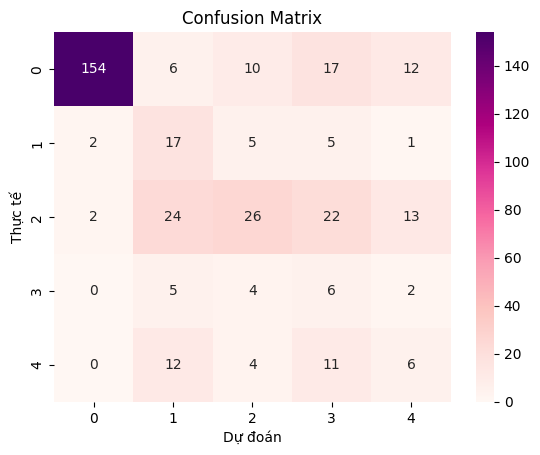

In [14]:
# tạo confusion_matrix
cm = confusion_matrix(y_test, y_pred)

# vẽ heatmap
sns.heatmap(cm, annot = True, cmap = "RdPu", fmt = 'd')

# thêm tiêu đề và nhãn trục
plt.title("Confusion Matrix")
plt.xlabel("Dự đoán")
plt.ylabel("Thực tế")

# hiển thị biểu đồ
plt.show()